# PW5 - Linear Regression

**Team:** Noé Berdoz, Michael Strefeler

## Our starting level

- **Noé Berdoz**: Bachelor in Business Information Technology (Informatique de gestion) at HE-Arc, completed in 2026. This programme focuses on software development and business processes and includes little mathematics, so matrix algebra, partial derivatives and the reasoning behind gradient descent were largely new to him. He had almost no experience in machine learning before this course.
- **Michael Strefeler**: Bachelor in Computer and Communication Systems (ISC) at HEIG-VD, completed in 2025, with a specialisation in data science, so he had already seen some machine learning before this course.

## Time spent

| Exercise | Time |
|---|---|
| Ex. 1 - Visualize the data | 2 h 00 |
| Ex. 2 - Normal equations | 2 h 00 |
| Ex. 3 - Batch gradient descent | 1 h 45 |
| Ex. 4 - Stochastic gradient descent | 2 h 00 |
| Ex. 5 - Review questions | 0 h 50 |
| Ex. 6 - Mini-batch gradient descent (optional) | 1 h 30 |
| Ex. 7 - Multi-variable regression (optional) | 1 h 00 |
| **Total** | **11 h 05** |

## Bonus request

We would like to apply for the bonus for this PW.

**Why.** We both went beyond the handout, each from our own starting point. For Noé, this topic was a real challenge, because his background contains little mathematics, he first had to rebuild the notions behind the exercises (the normal equation, the cost function and its gradient) before he could implement them, and he then spent extra time understanding why each method behaves as it does instead of stopping at code that runs. Michael used his data science background to go further on stochastic gradient descent and to complete both optional exercises. We believe this work, measured against our starting levels, is what the bonus is meant to reward.

**What we did as bonus**

- **Ex. 1** Descriptive statistics (skewness, mean and median) and the correlation between living area and rent.
- **Ex. 2 c** The optional part, with three client-readable metrics (MAE, RMSE and MAPE).
- **Ex. 3 b** The convergence-based stopping criterion is implemented, not only described.
- **Ex. 3 d** An explanation of the gap to the closed-form solution, and two fixes tested (separate learning rates and z-score normalisation).
- **Ex. 4 d** The optional stopping criterion is implemented in the stochastic loop.
- **Ex. 5 e** A gradient-free method (compass search) with its pseudo code.
- **Ex. 6 and 7** Both optional exercises are done.

## Imports

In [26]:
import random
import pandas as pd
import numpy as np
from numpy.linalg import inv
import matplotlib.pyplot as plt

## Load data

Define the path to the file containing the data

In [27]:
datafile = "lausanne-appart.csv"

Read the data

In [3]:
dataset = pd.read_csv(datafile)

Display first rows

In [4]:
dataset.head()

,living_area,nb_rooms,rent_price
0,69,3.0,1810
1,95,3.5,2945
2,21,1.5,685
3,20,1.0,720
4,33,1.5,830


## Exercise 1 - Visualize the data

a) Plot a histogram to visualize the distribution of the renting price

In [28]:
# Bonus code - Descriptive analysis
rent_price = dataset.rent_price.values

print("="*40)
print("DESCRIPTIVE STATISTICS - RENT PRICES")
print("="*40)

# We use :<15 to align labels to the left and :>10.2f to align numbers to the right
print(f"{'Minimum:':<15} {np.min(rent_price):>10.2f} CHF")
print(f"{'Maximum:':<15} {np.max(rent_price):>10.2f} CHF")
print("-" * 40)
print(f"{'Mean:':<15} {np.mean(rent_price):>10.2f} CHF")
print(f"{'Median:':<15} {np.median(rent_price):>10.2f} CHF")
print(f"{'Skewness:':<15} {dataset.rent_price.skew():>10.4f}")
print("="*40)

DESCRIPTIVE STATISTICS - RENT PRICES
Minimum:            685.00 CHF
Maximum:           7383.00 CHF
----------------------------------------
Mean:              2378.24 CHF
Median:            2145.00 CHF
Skewness:           1.3354


The rent prices show a positive skewness of 1.3354. Since the mean (2378.24 CHF) is higher than the median (2145.00 CHF), the distribution is right-skewed, indicating that a few expensive apartments are pulling the average upwards.

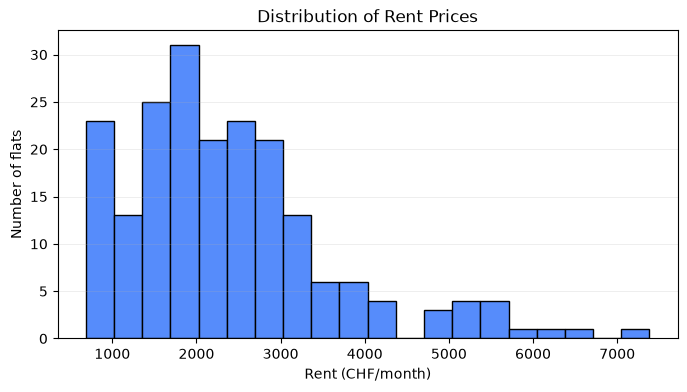

In [29]:
# Your code here
plt.figure(figsize=(8, 4))
plt.hist(rent_price, bins=20, edgecolor='black')
plt.xlabel("Rent (CHF/month)")
plt.ylabel("Number of flats")
plt.title("Distribution of Rent Prices")
plt.grid(axis='y', alpha=0.3)
plt.show()



From this histogram, we can see that the rental market distribution is unimodal and characterized by a high concentration of affordable housing between 1,500 and 2,500 CHF. However, the market is heavily influenced by a luxury segment (outliers), which creates a long right tail and shifts the average rent higher than the typical (median) rent.

b) Plot a histogram to visualize the distribution of the living area

In [30]:
# Bonus code - Descriptive analysis
living_area = dataset.living_area.values

print("="*40)
print("DESCRIPTIVE STATISTICS - LIVING AREAS")
print("="*40)

# We use :<15 to align labels to the left and :>10.2f to align numbers to the right
print(f"{'Minimum:':<15} {np.min(living_area):>10.2f} m^2")
print(f"{'Maximum:':<15} {np.max(living_area):>10.2f} m^2")
print("-" * 40)
print(f"{'Mean:':<15} {np.mean(living_area):>10.2f} m^2")
print(f"{'Median:':<15} {np.median(living_area):>10.2f} m^2")
print(f"{'Skewness:':<15} {dataset.living_area.skew():>10.4f}")
print("="*40)

DESCRIPTIVE STATISTICS - LIVING AREAS
Minimum:             13.00 m^2
Maximum:            240.00 m^2
----------------------------------------
Mean:                81.20 m^2
Median:              80.00 m^2
Skewness:           0.7413


The distribution of living areas exhibits a positive skewness of 0.7413. Since the mean (81.20 $m^2$) is higher than the median (80.00 $m^2$), the distribution is right-skewed. This indicates that the presence of larger apartments (up to 240 $m^2$) is pulling the average upwards, away from the median. The distribution of the living area mirrors the distribution of rent prices, suggesting that the premium prices in the dataset are driven by the larger properties (outliers in area).

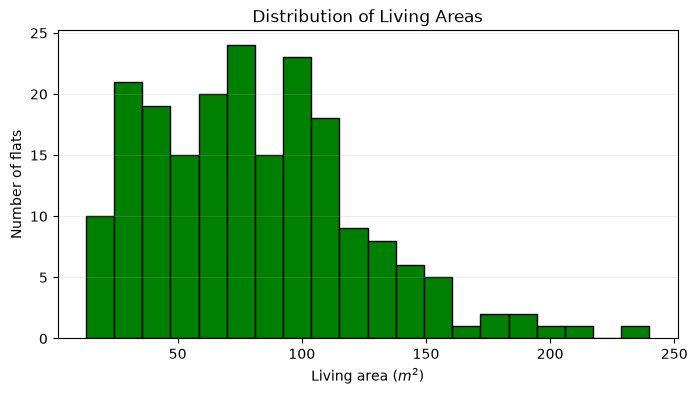

In [31]:
# Your code here
plt.figure(figsize=(8, 4))
plt.hist(living_area, bins=20, color='green', edgecolor='black')
plt.xlabel("Living area ($m^2$)")
plt.ylabel("Number of flats")
plt.title("Distribution of Living Areas")
plt.title("Distribution of Living Areas")
plt.grid(axis='y', alpha=0.3)
plt.show()


From this histogram, we can see that the living area distribution is unimodal and characterized by a high concentration of properties between 30 and 100 $m^2$. However, the distribution is heavily influenced by large-sized properties (outliers), which creates a long right tail and shifts the average area higher than the median.

c) Plot a scatter plot of renting price as a function of living area

In [9]:
# bonus code
correlation = dataset['living_area'].corr(dataset['rent_price'])
print(f"Correlation coefficient: {correlation:.4f}")

Correlation coefficient: 0.9042


We observe a strong positive correlation of 0.9 between living area and rent price, confirming the intuitive relationship.

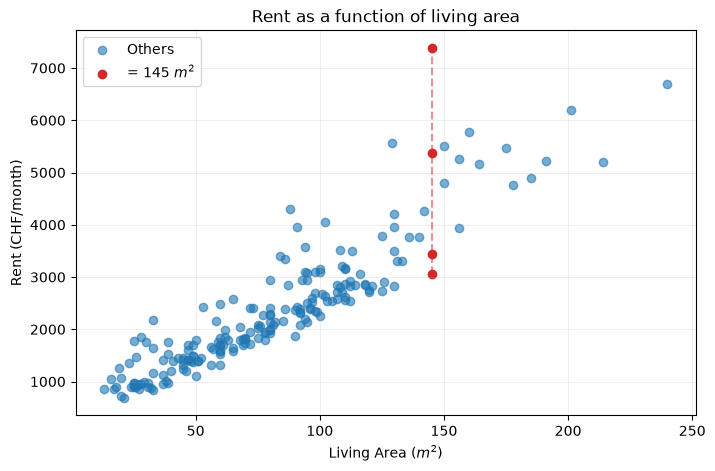

In [25]:
# Your code here

# Convert to numpy arrays so we can do element-wise maths and filter with masks
living_area = np.asarray(living_area)
rent_price = np.asarray(rent_price)

# Boolean masks, True where the point belongs to that group
is_145 = living_area == 145 # exactly 145 m^2
is_other = ~is_145  # all the rest

plt.figure(3, figsize=(8, 5))
plt.scatter(living_area[is_other], rent_price[is_other], color="tab:blue", alpha=0.6, label="Others")
plt.scatter(living_area[is_145], rent_price[is_145], color="tab:red", label="= 145 $m^2$")

# Dashed vertical lines showing the price gap between flats of 145m^2
plt.vlines(145, rent_price[is_145].min(), rent_price[is_145].max(), color="tab:red", linestyle="--", alpha=0.5)

plt.xlabel("Living Area ($m^2$)")
plt.ylabel("Rent (CHF/month)")
plt.title("Rent as a function of living area")
plt.grid(axis='both', alpha=0.3)
plt.legend()
plt.show()

From this scatter plot, we can see that the distribution shows heteroscedasticity. The error variance appears to increase as the living area and rent increase. We can see for example a significant variance at the 145 $m^2$ mark. Despite not being the maximum surface area, the 145 $m^2$ group includes high-value outliers (reaching over 7,000 CHF!). This price discrepancy suggests that other latent variables significantly influence the rental price, making the relationship non-trivial.

## Exercise 2 - Normal equations for linear regression

a) Implement the closed form solution to this problem using the following normal equation:

<div><div style="display: table-cell; width: 100%;"><center>$\theta = (X^{T}X)^{-1}X^{T}\vec{y}$</center></div><div style="display: table-cell; width: 100%;">$(3)$</div></div>

Assuming $x$ is the living area and $y$ is the renting price. Use `numpy` for the vector operations. Plot the computed line on top of the scatter plot of exercise 1.

---------------------------------------------
           NORMAL EQUATION RESULTS
---------------------------------------------
Dataset size (N) : 201
X shape          : (201, 2)
y shape          : (201,)
---------------------------------------------
theta_0 (intercept) : 240.08 CHF
theta_1 (slope)     : 26.33 CHF/m2
Model equation      : Rent = 240.08 + 26.33 * Area
---------------------------------------------


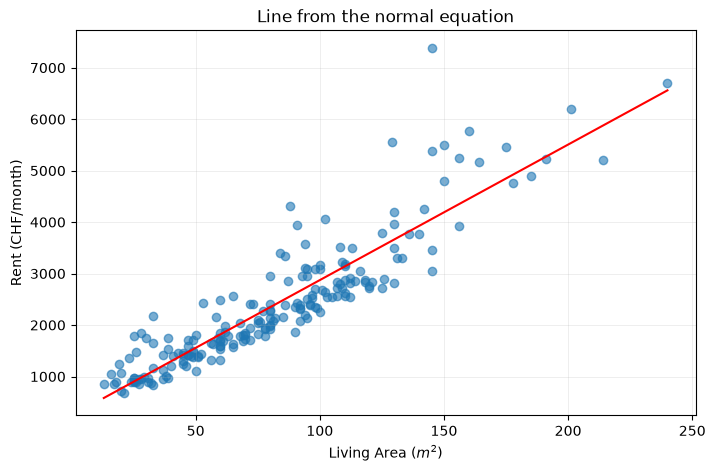

In [70]:
# Your code here
N = len(living_area)
X = np.ones((N, 2)) # 201 rows of [1., 1.]
X[:, 1] = living_area # column 1 gets the living areas
y = rent_price

XtX = X.T.dot(X)
Xty = X.T.dot(y)
XtX_inv = inv(XtX)

theta = XtX_inv.dot(Xty)

## Clean output
print("-" * 45)
print(" "*11 + "NORMAL EQUATION RESULTS")
print("-" * 45)
print(f"Dataset size (N) : {N}")
print(f"X shape          : {X.shape}")
print(f"y shape          : {y.shape}")
print("-" * 45)
print(f"theta_0 (intercept) : {theta[0]:.2f} CHF")
print(f"theta_1 (slope)     : {theta[1]:.2f} CHF/m2")
print(f"Model equation      : Rent = {theta[0]:.2f} + {theta[1]:.2f} * Area")
print("-" * 45)

## Regression plot
x_line = np.linspace(np.min(living_area), np.max(living_area))
y_line = theta[0] + theta[1] * x_line

plt.figure(4, figsize=(8, 5))
plt.scatter(living_area, rent_price, color="tab:blue", alpha=0.6)
plt.plot(x_line, y_line, color="red")
plt.xlabel("Living Area ($m^2$)")
plt.ylabel("Rent (CHF/month)")
plt.title("Line from the normal equation")
plt.grid(axis='both', alpha=0.3)
plt.show()


b) Compute the overall cost value according to the following equation:

<div><div style="display: table-cell; width: 100%;"><center>$J(\theta) = \frac{1}{2N} \sum_{n=1}^{N} (h_{\theta}(\mathbf{x}_{n}) - y_{n})^{2}$</center></div><div style="display: table-cell; width: 100%;">$(2)$</div></div>

In [87]:
# Your code here

## Compute predictions and cost
y_hat = X.dot(theta)
residuals = y_hat - y
sum_of_squared_erros = np.sum(residuals ** 2)
J = sum_of_squared_erros / (2 * N)

## Show first 3 samples result as preview
df_preview = pd.DataFrame(
    {
        "Area (m2)": living_area[:3],
        "y (True)": y[:3],
        "y_hat": y_hat[:3].round(2),
        "Error": residuals[:3].round(2),
        "Sq Error": (residuals[:3] ** 2).round(2),
    }
)
width = 50

print("-" * width)
print("SAMPLE PREDICTIONS (FIRST 3 ROWS)".center(width))
print("-" * width)
print(df_preview.to_string(index=False))
print("-" * width)

## Show cost function summary
print("\n" + "-" * width)
print("COST FUNCTION EVALUATION : J(theta)".center(width))
print("-" * width)
print(f"Dataset size (N)        : {N}")
print(f"Sum of Squared Errors   : {sum_of_squared_erros:.2f}")
print(f"Cost value J(theta)     : {J:.2f}")
print("-" * width)



--------------------------------------------------
        SAMPLE PREDICTIONS (FIRST 3 ROWS)         
--------------------------------------------------
 Area (m2)  y (True)   y_hat   Error  Sq Error
        69      1810 2057.01  247.01  61016.12
        95      2945 2741.66 -203.34  41348.20
        21       685  793.06  108.06  11676.54
--------------------------------------------------

--------------------------------------------------
       COST FUNCTION EVALUATION : J(theta)        
--------------------------------------------------
Dataset size (N)        : 201
Sum of Squared Errors   : 55490053.03
Cost value J(theta)     : 138034.96
--------------------------------------------------


c) The cost value reflects the performance of your system. Is this cost value *readable* for a client of your system ? What other metric could we use to make it more readable to the client ? Optional: implement it.

No, the cost value $J(\theta)$ is not readable for a client. The residuals are squared, $J(\theta)$ is expressed in squared Swiss Francs ($\text{CHF}^2$) and this unit has no real sense as a financial interpretation for a client.

But fortunately there are easy ways to show results that will talk to a client, here is the three alternative metrics we can use:

**RMSE (Root Mean Squared Error)**
$$\text{RMSE} = \sqrt{\frac{1}{N} \sum_{n=1}^{N} (y_n - \hat{y}_n)^2}$$

The RMSE restores the error unit to CHF while penalizing large outliers more severely than MAE due to the squaring step.

**MAE (Mean Absolute Error)**
$$\text{MAE} = \frac{1}{N} \sum_{n=1}^{N} \vert{}y_n - \hat{y}_n\vert{}$$

The MAE measures the average magnitude of errors in raw CHF. A client then can understand *"on average, predictions are off by X francs."*

**MAPE (Mean Absolute Percentage Error)**
$$\text{MAPE} = \frac{1}{N} \sum_{n=1}^{N} \left\vert{}\frac{y_n - \hat{y}_n}{y_n}\right\vert{} \times 100\%$$

The MAPE expresses relative inaccuracy as a percentage of the actual rent. *(Limitation: MAPE can become unstable if target values approach zero).*

In [98]:
# bonus code

## Implementation of RMSE
rmse = np.sqrt(np.mean(residuals ** 2))

## Implementation of MAE
mae = np.mean(np.abs(residuals))

## Implementation of MAPE
mape = np.mean(np.abs(residuals) / y) * 100

# Show a clean output
print("-" * width)
print("CLIENT-FRIENDLY PERFORMANCE METRICS".center(width))
print("-" * width)
print(f"Cost Value J(theta) : {J:10.2f} CHF^2 (uninterpretable)")
print("-" * width)
print(f"MAE                 : {mae:10.2f} CHF")
print(f"RMSE                : {rmse:10.2f} CHF")
print(f"MAPE                : {mape:10.2f} %")
print("-" * width)
print(f"Interpretation: On average, the rent is off by {mae:.0f} CHF ({mape:.1f}%).")
print("-" * width)


--------------------------------------------------
       CLIENT-FRIENDLY PERFORMANCE METRICS        
--------------------------------------------------
Cost Value J(theta) :  138034.96 CHF^2 (uninterpretable)
--------------------------------------------------
MAE                 :     368.18 CHF
RMSE                :     525.42 CHF
MAPE                :      15.40 %
--------------------------------------------------
Interpretation: On average, the rent is off by 368 CHF (15.4%).
--------------------------------------------------


## Exercise 3 - Gradient descent for linear regression

Implement the _full batch_ gradient descent algorithm for the previous problem. As seen in the
theory, the update rules are:

<div><div style="display: table-cell; width: 100%;"><center>$\theta_{0} \leftarrow \theta_{0} - \alpha \frac{1}{N} \sum_{n=1}^{N} (h_{\theta}(\mathbf{x}_{n}) - y_{n})$</center></div><div style="display: table-cell; width: 100%;">$(6)$</div></div>

<div><div style="display: table-cell; width: 100%;"><center>$\theta_{1} \leftarrow \theta_{1} - \alpha \frac{1}{N} \sum_{n=1}^{N} (h_{\theta}(\mathbf{x}_{n}) - y_{n}) x_{n,1}$</center></div><div style="display: table-cell; width: 100%;">$(7)$</div></div>

**Remark** You need to iterate several times over the training set. If you have problems of convergence, you need to use a smaller value of $\alpha$. Values such as $0.000001$ are common.

In [99]:
# Your code here
x = dataset['living_area'].values
y = dataset['rent_price'].values
N = len(x)

alpha = 0.000001
n_epochs = 10000
theta0 = 0.0
theta1 = 0.0
costs = []

for epoch in range(n_epochs):
    h = theta0 + theta1 * x
    error = h - y
    costs.append(np.sum(error ** 2) / (2 * N))
    theta0 = theta0 - alpha * np.sum(error) / N
    theta1 = theta1 - alpha * np.sum(error * x) / N

print('theta0 = ', theta0)
print('theta1 = ', theta1)

theta0 =  0.7881236391785441
theta1 =  28.65145363492427


a) Plot the cost value (Equation 2) as a function of the iterations. What do you observe?

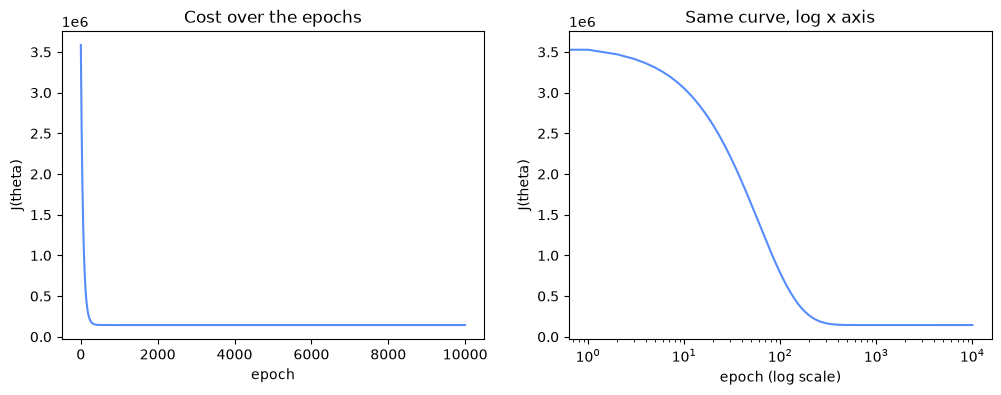

J at the start      :  3585070.1815920398
J after 100 epochs  :  783558.8380617645
J after 500 epochs  :  144922.8515194854
J after 1000 epochs :  144159.35280506394
J after 9999 epochs :  144135.74309911398


In [106]:
# Your code here
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(costs)
plt.xlabel('epoch')
plt.ylabel('J(theta)')
plt.title('Cost over the epochs')

plt.subplot(1, 2, 2)
plt.plot(costs)
plt.xscale('log')
plt.xlabel('epoch (log scale)')
plt.ylabel('J(theta)')
plt.title('Same curve, log x axis')
plt.show()

print('J at the start      : ', costs[0])
print('J after 100 epochs  : ', costs[100])
print('J after 500 epochs  : ', costs[500])
print('J after 1000 epochs : ', costs[1000])
print('J after 9999 epochs : ', costs[9999])


The cost function $J(θ)$ decreases monotonically, confirming successful convergence. The model exhibits rapid learning in the first 100 epochs, followed by a plateau. We observe convergence around epoch 1,000, as the cost stabilizes at around $1.4 \times 10^5$, meaning further iterations yield diminishing returns. The logarithmic scale plot confirms the smooth transition from rapid error reduction to the final stable state.

b) Imagine a stopping criterion, i.e. when do we stop iterating on the training set?

There are two main strategies to stop the iterations:

* **A fixed number of epochs:** We stop after a predetermined number of iterations (e.g., 10,000).
* **Convergence-based criterion:** We stop when the relative decrease in the cost function becomes smaller than a threshold $\epsilon$, mathematically expressed as:
$$\frac{J_{n-1} - J_n}{J_n} < \epsilon$$
This allows us to save computation time once the model has reached a stable state.

In [108]:
# bonus code

## Implementation of convergence-based criterion
eps = 0.000001
max_epochs = 10000
theta0_s = 0.0
theta1_s = 0.0
costs_s = []

for epoch in range(max_epochs):
    error = theta0_s + theta1_s * x - y
    costs_s.append(np.sum(error ** 2) / (2 * N))
    if epoch > 0 and (costs_s[-2] - costs_s[-1]) / costs_s[-1] < eps:
        break
    theta0_s = theta0_s - alpha * np.sum(error) / N
    theta1_s = theta1_s - alpha * np.sum(error * x) / N

print('stopped after', epoch, 'epochs')
print('J =', costs_s[-1])
print('theta =', theta0_s, theta1_s)

stopped after 769 epochs
J = 144168.02882846948
theta = 0.31657762978657084 28.611668496955236


c) Plot the computed line $h_{\theta}(\mathbf{x})$ on top of the scatter plot of exercise 1.

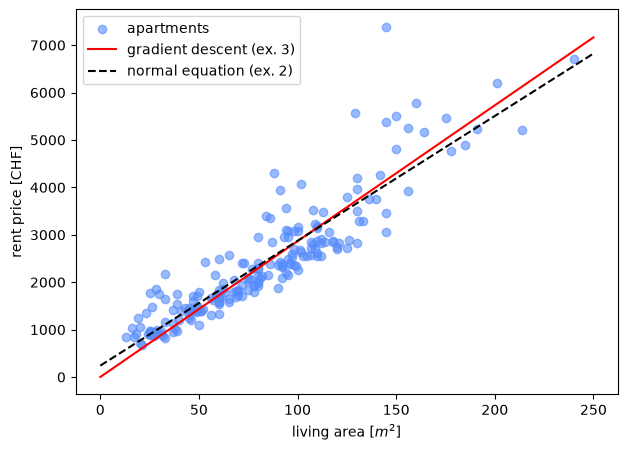

gradient descent: 0.7881236391785441 28.65145363492427
normal equation : [240.07710727  26.33242457]


In [139]:
# Your code here
X = np.column_stack([np.ones(N), x])
theta_normal_equation = inv(X.T @ X) @ X.T @ y

xs = np.array([0, 250])
plt.figure(figsize=(7, 5))
plt.scatter(x, y, label='apartments', alpha=0.6)
plt.plot(xs, theta0 + theta1 * xs, color='red', label='gradient descent (ex. 3)')
plt.plot(xs, theta_normal_equation[0] + theta_normal_equation[1] * xs, color='black', linestyle='--', label='normal equation (ex. 2)')
plt.xlabel('living area [$m^2$]')
plt.ylabel('rent price [CHF]')
plt.legend()
plt.show()
print('gradient descent:', theta0, theta1)
print('normal equation :', theta_normal_equation)

The figure shows that the line of gradient descent starts almost at the origin and is steeper. The two lines cross at around 100 $m^2$. For smaller appartments, gradient descent predicts lower rents, and for bigger apartments higher rents. Both lines follow the cloud well, and the difference only shows at the two ends.

d) Compute the final cost value according to Equation 2 and compare it to the one of exercise 2. What can you conclude?

In [158]:
# Your code here
J_gradient_descent = np.sum((theta0 + theta1 * x - y) ** 2) / (2 * N)
J_normal_equation = np.sum((theta_ne[0] + theta_ne[1] * x - y) ** 2) / (2 * N)

diff_abs = J_gradient_descent - J_normal_equation
diff_rel = (diff_abs / J_normal_equation) * 100
rmse_gradient_descent = np.sqrt(2 * J_gradient_descent)
rmse_normal_equation = np.sqrt(2 * J_normal_equation)

width = 65
print("-" * width)
print("COST COMPARISON: GRADIENT DESCENT vs NORMAL EQUATION".center(width))
print("-" * width)
print(f"{'Metric':<23} | {'Gradient Descent':<18} | {'Normal Equation':<18}")
print("-" * width)
print(f"{'Cost J(theta)':<23} | {J_gradient_descent:<18.2f} | {J_normal_equation:<18.2f}")
print(f"{'RMSE':<23} | {rmse_gradient_descent:<18.2f} | {rmse_normal_equation:<18.2f}")
print("-" * width)
print(f"{'Absolute Difference':<23} : {diff_abs:.2f} CHF²")
print(f"{'Relative Difference':<23} : {diff_rel:.2f} %")
print(f"{'RMSE Difference':<23} : {rmse_gradient_descent - rmse_normal_equation:.2f} CHF")
print("-" * width)

-----------------------------------------------------------------
       COST COMPARISON: GRADIENT DESCENT vs NORMAL EQUATION      
-----------------------------------------------------------------
Metric                  | Gradient Descent   | Normal Equation   
-----------------------------------------------------------------
Cost J(theta)           | 144135.74          | 138034.96         
RMSE                    | 536.91             | 525.42            
-----------------------------------------------------------------
Absolute Difference     : 6100.78 CHF²
Relative Difference     : 4.42 %
RMSE Difference         : 11.49 CHF
-----------------------------------------------------------------


The Normal Equation yields a lower cost than Gradient Descent because it provides the exact analytical solution (the global minimum). The Gradient Descent result is slightly higher (by approximately 4.4%), which indicates that the algorithm has approached the minimum but has not yet fully converged to the optimal $\theta$. This demonstrates that Gradient Descent is an iterative approximation of the exact solution provided by the Normal Equation.

The Normal Equation finds the exact best solution, while Gradient Descent ends up slightly higher (+4.4%). This shows that 10,000 epochs are not enough for Gradient Descent to fully finish. The main issue is the scale of the data. Apartment sizes ($x$) are much larger than 1, the slope $\theta_1$ reaches the right area quickly, but the intercept $\theta_0$ moves far too slowly. Furthermore, because our dataset has only one feature ($d=1$, meaning just two parameters to fit), computing the Normal Equation requires inverting a tiny $2 \times 2$ matrix, which is instantaneous. For a small problem like this, the Normal Equation is clearly the better choice because it gives the exact result immediately without hyperparameter tuning or heavy computation.

*Bonus: The cell below explores two solutions to help Gradient Descent reach the minimum in fewer epochs, by tuning a separate learning rate for each parameter, or standardizing $x$ with Z-scores.*

In [172]:
# bonus code

## Resolving convergence with 2 learning rates vs Z-normalisation

### Approach 1: Gradient Descent with 2 learning rates (alpha0=0.1, alpha1=1e-6)
t0_lr, t1_lr = 0.0, 0.0
for _ in range(10000):
    err = t0_lr + t1_lr * x - y
    t0_lr -= 0.1 * np.sum(err) / N
    t1_lr -= 0.000001 * np.sum(err * x) / N
J_two_lr = np.sum((t0_lr + t1_lr * x - y) ** 2) / (2 * N)

### Approach 2: Gradient Descent with Z-score normalisation (alpha=0.1, 100 epochs only)
x_mean, x_std = np.mean(x), np.std(x)
x_norm = (x - x_mean) / x_std

t0_zn, t1_zn = 0.0, 0.0
for _ in range(100):
    err_n = t0_zn + t1_zn * x_norm - y
    t0_zn -= 0.1 * np.sum(err_n) / N
    t1_zn -= 0.1 * np.sum(err_n * x_norm) / N

#### Convert parameters back to original CHF and m^2
t0_zn_back = t0_zn - t1_zn * x_mean / x_std
t1_zn_back = t1_zn / x_std
J_zn = np.sum((t0_zn_back + t1_zn_back * x - y) ** 2) / (2 * N)

### Show clean output
print(f"{'Method':<28} | {'Epochs':<8} | {'theta0':<8} | {'theta1':<8} | {'Cost J':<11} | {'Diff %':<8}")
print("-" * 82)
runs = [
    ("Normal Equation (Exact)", "-", theta_ne[0], theta_ne[1], J_normal_equation),
    ("Standard GD (3d)", "10 000", theta0, theta1, J_gradient_descent),
    ("GD (2 Learning Rates)", "10 000", t0_lr, t1_lr, J_two_lr),
    ("GD (Z-Normalised)", "100", t0_zn_back, t1_zn_back, J_zn),
]

for name, ep, th0, th1, j_val in runs:
    diff = ((j_val - J_normal_equation) / J_normal_equation) * 100
    print(f"{name:<28} | {ep:<8} | {th0:<8.2f} | {th1:<8.2f} | {j_val:<11.2f} | {diff:>6.2f} %")

Method                       | Epochs   | theta0   | theta1   | Cost J      | Diff %  
----------------------------------------------------------------------------------
Normal Equation (Exact)      | -        | 240.08   | 26.33    | 138034.96   |   0.00 %
Standard GD (3d)             | 10 000   | 0.79     | 28.65    | 144135.74   |   4.42 %
GD (2 Learning Rates)        | 10 000   | 240.08   | 26.33    | 138034.96   |   0.00 %
GD (Z-Normalised)            | 100      | 240.07   | 26.33    | 138034.96   |   0.00 %


The benchmark highlights how data scaling dictates optimization dynamics. While introducing parameter-specific learning rates ($\alpha_0=0.1, \alpha_1=10^{-6}$) compensates for gradient discrepancies and eventually converges within 10,000 epochs, it introduces tedious and problem-dependent hyperparameter tuning. In contrast, Z-score feature normalization directly fixes the underlying geometry by transforming the narrow, elongated error valley into a symmetric, circular bowl. This enables a single standard learning rate ($\alpha=0.1$) to reach the exact analytical optimum in merely 100 epochs, underscoring why feature standardization is a fundamental prerequisite for gradient descent.

## Exercise 4 - Stochastic gradient descent for linear regression

Implement the stochastic gradient descent algorithm for the previous problem. As seen in the theory, the update rules are:

<div><div style="display: table-cell; width: 100%;"><center>$\theta_{i} \leftarrow \theta_{i} - \alpha (h_{\theta}(\mathbf{x}_{n}) - y_{n}) x_{n,i}$</center></div><div style="display: table-cell; width: 100%;">$(8)$</div></div>

In [33]:
X = dataset.living_area.values
y = dataset.rent_price.values

In [34]:
def stochastic_gradient_descent(X, y, verbose=True):
    N = len(X)

    # randomly initialize thetas
    theta_0 = random.uniform(0.0, float(y.max())) # y interceot
    theta_1 = random.uniform(-1.0, 1.0) # slope

    print(f"Initial random values for theta_0 (y intercept) {theta_0:.4f} and theta_1 (slope) {theta_1:.4f}")
    
    x_mean, x_std = X.mean(), X.std()
    x_norm = (X - x_mean) / x_std

    # Training parameters
    max_iters = 200_000
    check_every = 1000
    tolerance = 1e-3
    prev_loss = None
    alpha = 0.0001

    # History used for animations
    history = [] # (iteration, intercept, slope) in original units
    history.append((0, theta_0 - theta_1 * x_mean / x_std, theta_1 / x_std))
    record_every = 50

    for it in range(1, max_iters + 1):
        sample_n = random.randrange(0, N)
        x_n = x_norm[sample_n]
        y_n = y[sample_n]

        error = (theta_0 + theta_1 * x_n) - y_n
        theta_0 -= alpha * error
        theta_1 -= alpha * error * x_n

        if it % record_every == 0:
            history.append((it, theta_0 - theta_1 * x_mean / x_std, theta_1 / x_std))

        if it % check_every == 0:
            loss = np.mean((theta_0 + theta_1 * x_norm - y) ** 2) / 2
            if verbose:
                print(f"iter {it}: loss = {loss:.2f}, theta_0 = {theta_0:.3f}, theta_1 = {theta_1:.3f}")

            if not np.isfinite(loss):
                print("Diverged: try a smaller alpha")
                break
            if prev_loss is not None and abs(prev_loss - loss) < tolerance * prev_loss:
                print("Converged")
                break
            prev_loss = loss

    intercept = theta_0 - theta_1 * x_mean / x_std
    slope = theta_1 / x_std
    return history, intercept, slope

In [35]:
history, intercept, slope = stochastic_gradient_descent(X, y)

Initial random values for theta_0 (y intercept) 1477.7911 and theta_1 (slope) -0.9731
iter 1000: loss = 964830.93, theta_0 = 1569.265, theta_1 = 113.094
iter 2000: loss = 813244.69, theta_0 = 1645.450, theta_1 = 210.762
iter 3000: loss = 701710.54, theta_0 = 1712.438, theta_1 = 285.591
iter 4000: loss = 598525.38, theta_0 = 1775.938, theta_1 = 365.533
iter 5000: loss = 512575.68, theta_0 = 1833.500, theta_1 = 440.108
iter 6000: loss = 445421.57, theta_0 = 1885.114, theta_1 = 503.079
iter 7000: loss = 388691.39, theta_0 = 1934.468, theta_1 = 560.964
iter 8000: loss = 344187.76, theta_0 = 1975.572, theta_1 = 612.506
iter 9000: loss = 304351.95, theta_0 = 2015.234, theta_1 = 664.495
iter 10000: loss = 273095.27, theta_0 = 2052.006, theta_1 = 708.081
iter 11000: loss = 247991.01, theta_0 = 2083.735, theta_1 = 747.733
iter 12000: loss = 229077.95, theta_0 = 2110.428, theta_1 = 780.461
iter 13000: loss = 213719.48, theta_0 = 2134.864, theta_1 = 809.128
iter 14000: loss = 199636.95, theta_0 =

a) Plot the computed line $h_{\theta}(\mathbf{x})$ on top of the scatter plot of exercise 1.

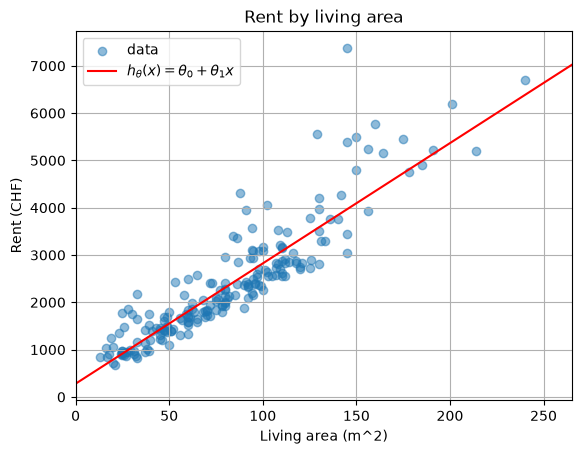

In [36]:
# Your code here
def line_on_scatter(X, y, intercept, slope):
    plt.title("Rent by living area")
    plt.xlabel("Living area (m^2)")
    plt.ylabel("Rent (CHF)")
    plt.scatter(X, y, alpha=0.5, label="data")

    # h_theta(x) = theta_0 + theta_1 * x
    x_line = np.array([0.0, X.max() + 25])
    y_line = intercept + slope * x_line
    plt.plot(x_line, y_line, color="red", label=r"$h_{\theta}(x) = {\theta}_0 + {\theta}_1x$")

    plt.xlim(0.0, X.max() + 25)
    plt.legend()
    plt.grid(True)
    plt.show()

line_on_scatter(X, y, intercept, slope)

Animation of SGD converging (made by Claude)

In [37]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML

def animate_line_on_scatter(history, X, y, name):
    hist = np.array(history)   # columns: iteration, intercept, slope

    # Pick ~150 frames, spaced logarithmically so the fast early movement is visible
    idx = np.unique(np.geomspace(1, len(hist), 150).astype(int)) - 1

    x_line = np.array([0.0, X.max() + 25])

    fig, ax = plt.subplots()
    ax.scatter(X, y, alpha=0.5, label="data")
    slope_ref, intercept_ref = np.polyfit(X, y, 1)
    ax.plot(x_line, intercept_ref + slope_ref * x_line, "k--", lw=1, label="exact fit (polyfit)")
    line, = ax.plot([], [], color="red", lw=2, label=r"$h_{\theta}(x)$")
    text = ax.text(0.97, 0.05, "", transform=ax.transAxes, ha="right")

    ax.set_xlim(0.0, X.max() + 25)
    ax.set_ylim(0, y.max() * 1.1)
    ax.set_title("Rent by living area")
    ax.set_xlabel("Living area (m^2)")
    ax.set_ylabel("Rent (CHF)")
    ax.grid(True)
    ax.legend(loc="upper left")

    def update(frame):
        it, b, w = hist[idx[frame]]
        line.set_data(x_line, b + w * x_line)
        text.set_text(f"iteration {int(it)}")
        return line, text

    anim = FuncAnimation(fig, update, frames=len(idx), interval=50, blit=True)
    plt.close(fig)   # stops Jupyter from also showing a static copy

    HTML(anim.to_jshtml())
    anim.save(name, writer=PillowWriter(fps=20))

animate_line_on_scatter(history, X, y, "stochastic_gradient_descent.gif")

b) How many samples do you need to visit for reaching the convergence?

It depends on how lucky we get and which parameters we use. After running the notebook multiple times it seems like convergence happens anywhere between 30'000 and 42'000 iterations.

Since each iteration of Stochastic Gradient Descent uses one sample, that is 30'000 to 42'000 sample visits. With 201 samples in the dataset, this is equivalent to $30'000 / 201 \approx 150$ up to $42'000 / 201 \approx 210$ passes over the data. Samples are drawn with replacement, so each one is visited many times, and SGD needs that many visits to converge.

c) How to observe the convergence? Propose a strategy to observe the convergence as in Ex 3 a), the problem being that we don’t have anymore a notion of epoch.

To observe convergence we calculated the loss of the regression during the SGD loop and if the value stops changing a lot, then it has converged.

Since each update uses a single random sample, we define a pseudo-epoch as N iterations. In our implementation check_every = 1000 already plays this role (1000 is about 5 passes over the 201 samples), and every check computes the loss over the whole dataset. To observe convergence, we store these loss values in a list and plot them against iterations divided by N. The curve drops steeply at first and then flattens into a noisy plateau, and that plateau is the convergence. It never becomes perfectly flat because with a constant alpha, SGD keeps jittering around the optimum.

d) Optional: What kind of stopping criterion could we use here? Propose a strategy.

Our current rule stops as soon as the loss changes by less than tolerance between two checks, but SGD noise can trigger this by accident. A more robust version is to stop only when that condition holds for several checks in a row (a patience of, say, 5), and reset the counter whenever a check shows a larger improvement. We keep max_iters as a safety cap and the isfinite check for divergence.

e) Compute the final cost value according to Equation 2 and compare it to the one of exercise 2 and 3. What can you conclude?

In [38]:
# Your code here
print(f'Final cost value {np.mean((intercept + slope * X - y) ** 2) / 2:.4f}')

Final cost value 139332.1485


TODO: Answer when ex 2 and 3 are done

## Exercise 5 - Review questions

a) The linear regression has a mathematical _closed form_ solution. Then, in which conditions would we prefer a gradient descent algorithm to compute the regression model?

Although the Normal Equation provides an exact analytical solution, Gradient Descent is preferred in the following conditions:

- **Large number of features:** Computing $(X^T X)^{-1}$ requires about $N \cdot D^2$ operations to build the matrix and $D^3$ operations to invert it. When $D$ is in the thousands, this $D^3$ step explodes and becomes computationally prohibitive, whereas one epoch of Gradient Descent scales at only about $2 \cdot N \cdot D$ operations.
- **Large datasets:** When the dataset is too massive to fit into RAM, Stochastic or Mini-batch Gradient Descent can train on small batches of data without loading the entire matrix into memory.
- **Incremental learning case:** When data arrives continuously in real time, Gradient Descent can incrementally update the parameters $\theta$ on the fly without recomputing the entire solution from scratch.
- **Matrix singularity ($X^T X$ is not invertible):** The Normal Equation fails if $(X^T X)$ cannot be inverted (e.g., when features are linearly dependent or when $D > N$).


Also, while linear regression with MSE has a closed-form solution, most machine learning models (e.g., Logistic Regression, Neural Networks) do not. Gradient Descent is a universal optimization framework that works across these models.

b) Outliers in a data set can be defined as values that are out of the "usual" range in comparison with other values. They typically come from noise or anomalies in the data capturing process. What is the impact of an outlier in the stochastic gradient descent process? What if we have many outliers? _Hint_: look at the equation of the MSE, and to the equation of the update rule.


Outliers affect both the loss function and the update rule, because both depend on the error $\bold{\red{(h_{\theta}(x_n)-y_n)}}$

In the MSE $J(\theta)=\frac{1}{2N}\sum_{n=1}^N\bold{\red{(h_{\theta}(x_n)-y_n)^2}}$, the error is squared, so an outlier with a large error contributes disproportionately to the sum and dominates the loss. The minimum of J is therefore pulled towards the outliers, and the resulting $\theta$ fits the bulk of the data less well.

In the SGD update $\theta_i \leftarrow \theta_i - \alpha(\bold{\red{h_{\theta}(x_n)-y_n})x_{n,i}}$, the step size is proportional to the error. Whenever the sample drawn is an outlier, the error is large and $\theta$ makes a big jump away from the good solution. Since SGD uses one sample at a time, there is no averaging over other points to dampen this, so the trajectory becomes noisy with spikes in the loss.

If there are only a few outliers, SGD is disturbed occasionally and can recover afterwards. With many outliers, these harmful updates occur frequently, so $\theta$ is constantly pulled away from the true trend: convergence becomes slow and unstable, the solution is biased towards the outliers, and with a large α the algorithm may even diverge.

c) In the case of stochastic gradient descent, what is the danger of having a too large or too small $\alpha$ value? Could you think of a better (more advanced) strategy as the one stated in Slide 36?

$\alpha$ too small: each update moves $\theta$ only a tiny bit, so SGD needs very many iterations to reach the minimum. It’s inefficient, and with a limited iteration budget it may stop before converging (like skiing down a slope in a snowplow position). It can also stall on plateaus or in poor local minima.

$\alpha$ too large: the updates overshoot the minimum and land higher on the opposite side of the valley, so the loss oscillates or even diverges, as in the right panel of the slide. In SGD this is worse, because the gradient estimates are noisy and a large step amplifies that noise. Even a moderate constant $\alpha$ means the iterates never settle exactly at the minimum and keep fluctuating around it.

Better strategy: instead of fixing $\alpha$ by hand, adapt it during training. A learning rate schedule (step decay, exponential decay, 1/t decay, cosine annealing) starts with a large $\alpha$ for fast early progress and shrinks it over time, so the iterates settle near the minimum. Adaptive optimizers such as AdaGrad, RMSProp or Adam adjust the step size per parameter based on the history of gradients. More recent research, such as AutoSGD[1] (2025), chooses the learning rate on the fly by comparing the performance of neighbouring larger and smaller rates.

Source [1] [AutoSGD arxiv.org](https://arxiv.org/html/2505.21651v1#abstract1)

d) Let's assume we expect that the target variable $y$ has a dependency to the square and to the cube of one of the feature $x_d$ in our multi-variable training set $(x_1, \ldots, x_d, \ldots, x_D)$. How would you proceed? Do we need to take precautions in terms of numerical stability?

We could add the features $x_d^2$ and $x_d^3$ to the training set, so that the model becomes $h_\theta(x) = \theta_0 + \sum_{i=1}^{D} \theta_i x_i + \theta_{D+1}\, x_d^2 + \theta_{D+2}\, x_d^3$

The model is still linear in the parameters $\theta$, so the same MSE and the same SGD update rule can be used, now with $D+2$ features: $\theta_i \leftarrow \theta_i - \alpha\,\big(h_\theta(x_n) - y_n\big)\, x_{n,i}$

Yes, numerical stability must be considered. The powers of $x_d$ have very different magnitudes from the other features ($x_d^3$ can be huge or vanishingly small) and are strongly correlated with each other. This leads to large gradient components, an ill-conditioned cost function, and therefore divergence or very slow convergence. To avoid this, the features should be normalized/standardized (e.g. zero mean and unit variance) before training:

$x' = \frac{x - \mu}{\sigma}$ and a suitably small learning rate $\alpha$ should be used.

e) _Advanced_. Could we use a descent algorithm without computing the gradient? If yes, give a pseudo code of the algorithm to find $(\theta_{0}, \theta_{1})$ using a linear regression $h_{\theta}(x) = \theta_0 + \theta_1 x$.

Yes, we can optimize the model without computing derivatives. Since we can compute the cost $J(\theta)$ for any parameter values, we only need to test if a small step in parameter space decreases the cost.

A common approach is the **Compass Search**:
1. We try taking a step forward ($+s$) and backward ($-s$) along each parameter one by one.
2. If a step lowers the cost $J$, we accept it immediately.
3. If no step around the current position improves $J$, we halve the step size ($s \leftarrow s / 2$) to search more locally.
4. We stop when the step size becomes smaller than a defined threshold.

But there is a trade-off, this method requires evaluating the cost function up to $2 \cdot D$ times per round (for $D$ parameters), making it computationally slower than gradient descent which gets the descent direction for all parameters in a single pass.

Here is the pseudo code for the Compass Search method:
```text
theta = (0, 0)
s = (100, 10)            # initial step sizes for theta0 and theta1
tol = (0.01, 0.0001)     # stopping tolerance
J_best = J(theta)

while s[0] > tol[0] or s[1] > tol[1]:
    improved = false

    for i in (0, 1):         # check theta0, then theta1
        for direction in (+1, -1):
            theta_candidate = theta
            theta_candidate[i] = theta[i] + direction * s[i]

            if J(theta_candidate) < J_best:
                theta = theta_candidate
                J_best = J(theta_candidate)
                improved = true
                break        # accept move and proceed to next parameter

    if not improved:
        s = s / 2            # no direction helped: shrink search radius

return theta



## Exercise 6 - Optional - Mini-batch gradient descent for linear regression

Implement the _mini-batch_ gradient descent algorithm for the previous problem, adding a parameter $B$ defining the size of the mini-batch.

In [39]:
# Your code here
# TODO: Remove this when Ex 3 is done, use real function instead
def batch_gradient_descent(X, y):
    return None, None, None

def mini_batch_gradient_descent(X, y, B):
    if B == len(X):
        print("B = N: running batch gradient descent")
        return batch_gradient_descent(X, y)
    elif B == 1:
        print("B = 1: running stochastic gradient descent")
        return stochastic_gradient_descent(X, y, False)
    
    N = len(X)

    # randomly initialize thetas
    theta_0 = random.uniform(0.0, float(y.max()))
    theta_1 = random.uniform(-1.0, 1.0)

    print(f"Initial random values for theta_0 (y intercept) {theta_0:.4f} and theta_1 (slope) {theta_1:.4f}")

    # normalize X (same as SGD)
    x_mean, x_std = X.mean(), X.std()
    x_norm = (X - x_mean) / x_std

    # Training parameters
    max_epochs = 5000
    tolerance = 1e-3
    prev_loss = None
    alpha = 0.01
    record_every = 1

    history = [(0, theta_0 - theta_1 * x_mean / x_std, theta_1 / x_std)]

    update_count = 0
    for epoch in range(1, max_epochs + 1):
        # shuffle once per epoch so every sample is used exactly once per epoch
        perm = np.random.permutation(N)
        x_shuf = x_norm[perm]
        y_shuf = y[perm]

        # walk through the data in chunks of B (the last batch may be smaller)
        for start in range(0, N, B):
            x_b = x_shuf[start:start + B]
            y_b = y_shuf[start:start + B]

            error = (theta_0 + theta_1 * x_b) - y_b   # shape (B,)
            grad_0 = np.mean(error)
            grad_1 = np.mean(error * x_b)

            theta_0 -= alpha * grad_0
            theta_1 -= alpha * grad_1
            update_count += 1

        if epoch % record_every == 0:
            history.append((update_count,
                            theta_0 - theta_1 * x_mean / x_std,
                            theta_1 / x_std))

        # convergence check on the full dataset loss, once per epoch
        loss = np.mean((theta_0 + theta_1 * x_norm - y) ** 2) / 2

        if not np.isfinite(loss):
            print("Diverged: try a smaller alpha")
            break
        if prev_loss is not None and abs(prev_loss - loss) < tolerance * prev_loss:
            print(f"Converged after {epoch} epochs")
            break
        prev_loss = loss

    intercept = theta_0 - theta_1 * x_mean / x_std
    slope = theta_1 / x_std
    return history, intercept, slope

In [40]:
history, intercept, slope = mini_batch_gradient_descent(X, y, 32)

Initial random values for theta_0 (y intercept) 4051.9190 and theta_1 (slope) -0.6693
Converged after 54 epochs


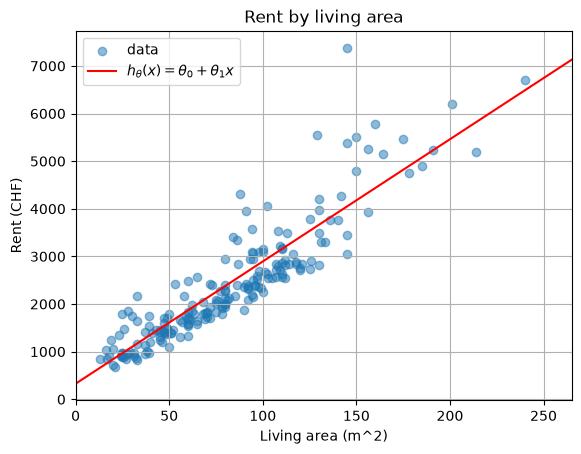

In [41]:
line_on_scatter(X, y, intercept, slope)

In [42]:
print(f'Final cost value {np.mean((intercept + slope * X - y) ** 2) / 2:.4f}')

Final cost value 138963.2776


In [43]:
animate_line_on_scatter(history, X, y, "mini_batch_gradient_descent.gif")

Check that when $B = N$, you fall back on the batch gradient descent solution, and when $B = 1$, you get the behaviour of stochastic gradient descent.

In [44]:
# Your code here
_, _, _ = mini_batch_gradient_descent(X, y, len(X))
_, _, _ = mini_batch_gradient_descent(X, y, 1)

B = N: running batch gradient descent
B = 1: running stochastic gradient descent
Initial random values for theta_0 (y intercept) 4583.3155 and theta_1 (slope) 0.7151
Converged


The cell above shows that we get the correct behavior when $B=N$ and $B=1$

## Exercise 7 - Optional - Multi-variable linear regression

**Hint** For these two exercises, you may need to perform a normalization of the input data, such as min-max rescaling or z-norm.

a) Implement one of the gradient descent algorithm (ex. 3-5) for the multi-variable linear regression assuming $x_1$ being the living area and $x_2$ the square of the living area. Plot the computed curve (second order) on top of the scatter plot of exercise 1. Do you observe a reduction in the loss?

In [45]:
# Your code here
def multi_stochastic_gradient_descent(X, y, verbose=True):
    N, D = X.shape  # D = number of features

    # randomly initialize thetas
    theta_0 = random.uniform(0.0, float(y.max()))             # y intercept
    theta = np.array([random.uniform(-1.0, 1.0) for _ in range(D)])  # one weight per feature

    print(f"Initial random values: theta_0 = {theta_0:.4f}, theta = {np.round(theta, 4)}")

    # Normalize each column independently
    x_mean = X.mean(axis=0)   # shape (D,)
    x_std = X.std(axis=0)     # shape (D,)
    x_norm = (X - x_mean) / x_std

    # Training parameters
    max_iters = 200_000
    check_every = 1000
    tolerance = 1e-3
    prev_loss = None
    alpha = 0.0001

    def to_original_units(theta_0, theta):
        slopes = theta / x_std
        intercept = theta_0 - np.sum(theta * x_mean / x_std)
        return intercept, slopes

    # History used for animations
    history = []  # (iteration, intercept, slopes) in original units
    intercept, slopes = to_original_units(theta_0, theta)
    history.append((0, intercept, slopes))
    record_every = 50

    for it in range(1, max_iters + 1):
        sample_n = random.randrange(0, N)
        x_n = x_norm[sample_n]      # shape (D,)
        y_n = y[sample_n]

        error = (theta_0 + np.dot(theta, x_n)) - y_n
        theta_0 -= alpha * error
        theta -= alpha * error * x_n   # updates all weights at once

        if it % record_every == 0:
            intercept, slopes = to_original_units(theta_0, theta)
            history.append((it, intercept, slopes))

        if it % check_every == 0:
            preds = theta_0 + x_norm @ theta
            loss = np.mean((preds - y) ** 2) / 2
            if verbose:
                print(f"iter {it}: loss = {loss:.2f}, theta_0 = {theta_0:.3f}, theta = {np.round(theta, 3)}")

            if not np.isfinite(loss):
                print("Diverged: try a smaller alpha")
                break
            if prev_loss is not None and abs(prev_loss - loss) < tolerance * prev_loss:
                print("Converged")
                break
            prev_loss = loss

    intercept, slopes = to_original_units(theta_0, theta)
    return history, intercept, slopes

In [46]:
# Feature matrix: x1 = area, x2 = area^2
X_poly = np.column_stack([X, X ** 2])   # shape (N, 2)

history, intercept, slopes = multi_stochastic_gradient_descent(X_poly, y)
theta_0, theta_1, theta_2 = intercept, slopes[0], slopes[1]
print(f"h(x) = {theta_0:.2f} + {theta_1:.3f}*x + {theta_2:.5f}*x^2")

Initial random values: theta_0 = 217.0279, theta = [0.5641 0.5132]
iter 1000: loss = 2502050.12, theta_0 = 419.347, theta = [88.429 82.151]
iter 2000: loss = 2007007.00, theta_0 = 606.848, theta = [174.527 166.856]
iter 3000: loss = 1643967.89, theta_0 = 771.542, theta = [235.659 225.392]
iter 4000: loss = 1349494.86, theta_0 = 922.067, theta = [290.203 277.7  ]
iter 5000: loss = 1100076.19, theta_0 = 1064.683, theta = [344.534 328.177]
iter 6000: loss = 918357.50, theta_0 = 1185.370, theta = [381.981 365.567]
iter 7000: loss = 773315.50, theta_0 = 1298.288, theta = [407.86  387.731]
iter 8000: loss = 647723.33, theta_0 = 1402.842, theta = [440.709 416.524]
iter 9000: loss = 551070.54, theta_0 = 1494.819, theta = [464.829 438.672]
iter 10000: loss = 475137.60, theta_0 = 1577.157, theta = [482.355 453.509]
iter 11000: loss = 411332.85, theta_0 = 1653.288, theta = [500.371 468.859]
iter 12000: loss = 359547.01, theta_0 = 1722.096, theta = [516.67  483.073]
iter 13000: loss = 316941.32, t

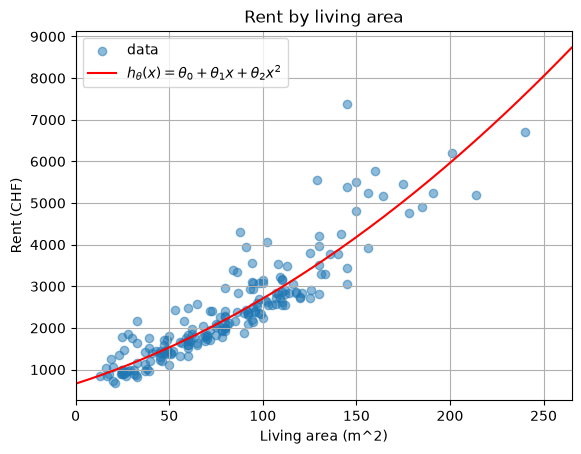

In [47]:
plt.title("Rent by living area")
plt.xlabel("Living area (m^2)")
plt.ylabel("Rent (CHF)")
plt.scatter(X, y, alpha=0.5, label="data")

x_curve = np.linspace(0.0, X.max() + 25, 200)
y_curve = theta_0 + theta_1 * x_curve + theta_2 * x_curve ** 2
plt.plot(x_curve, y_curve, color="red",
        label=r"$h_{\theta}(x) = \theta_0 + \theta_1 x + \theta_2 x^2$")

plt.xlim(0.0, X.max() + 25)
plt.legend()
plt.grid(True)
plt.show()

In [48]:
def animate_curve_on_scatter(history, X, y, name):
    # Split history into proper numeric arrays
    its    = np.array([h[0] for h in history], dtype=float)   # (T,)
    b0s    = np.array([h[1] for h in history], dtype=float)   # (T,)
    slopes_hist = np.array([h[2] for h in history], dtype=float)   # (T, 2)

    # ~150 frames, spaced logarithmically so the fast early movement is visible
    idx = np.unique(np.geomspace(1, len(its), 150).astype(int)) - 1

    x_curve = np.linspace(0.0, X.max() + 25, 200)

    fig, ax = plt.subplots()
    ax.scatter(X, y, alpha=0.5, label="data")

    # Exact quadratic fit as reference (polyfit returns highest degree first)
    c2, c1, c0 = np.polyfit(X, y, 2)
    ax.plot(x_curve, c0 + c1 * x_curve + c2 * x_curve ** 2, "k--", lw=1,
            label="exact fit (polyfit)")

    line, = ax.plot([], [], color="red", lw=2, label=r"$h_{\theta}(x)$")
    text = ax.text(0.97, 0.05, "", transform=ax.transAxes, ha="right")

    ax.set_xlim(0.0, X.max() + 25)
    ax.set_ylim(0, y.max() * 1.1)
    ax.set_title("Rent by living area")
    ax.set_xlabel("Living area (m^2)")
    ax.set_ylabel("Rent (CHF)")
    ax.grid(True)
    ax.legend(loc="upper left")

    def update(frame):
        k = idx[frame]
        y_curve = b0s[k] + slopes_hist[k, 0] * x_curve + slopes_hist[k, 1] * x_curve ** 2
        line.set_data(x_curve, y_curve)
        text.set_text(f"iteration {int(its[k])}")
        return line, text

    anim = FuncAnimation(fig, update, frames=len(idx), interval=50, blit=True)
    plt.close(fig)
    HTML(anim.to_jshtml())
    anim.save(name, writer=PillowWriter(fps=20))

animate_curve_on_scatter(history, X, y, "multi_stoch_gradient_descent.gif")

In [49]:
y_pred = intercept + X_poly @ slopes
final_cost = np.mean((y_pred - y) ** 2) / 2
print(f"Final cost value {final_cost:.4f}")

Final cost value 136666.0746


Our implementation of the univariate stochastic gradient descent has a final cost value of 139332.1485 (this value varies every time the code is run). The multivariate version has a final cost value of 136666.0746 which also changes each time.

After running the code multiple times, it seems like the multivariate version performs slightly better each time.

b) Implement one of the gradient descent algorithm (ex. 3-5) for the multi-variable linear regression assuming $x_1$ being the living area and $x_2$ the number of bedrooms. Do you observe a reduction in the loss?

In [50]:
# Your code here
# Feature matrix: x1 = living area, x2 = nb rooms
X_poly = np.column_stack([X, dataset.nb_rooms.values])   # shape (N, 2)

history, intercept, slopes = multi_stochastic_gradient_descent(X_poly, y)
theta_0, theta_1, theta_2 = intercept, slopes[0], slopes[1]
print(f"h(x) = {theta_0:.2f} + {theta_1:.3f}*area + {theta_2:.3f}*rooms")

Initial random values: theta_0 = 2013.6665, theta = [-0.6518  0.7691]
iter 1000: loss = 627084.28, theta_0 = 2047.726, theta = [101.133  90.739]
iter 2000: loss = 487936.11, theta_0 = 2082.077, theta = [188.297 165.001]
iter 3000: loss = 394639.67, theta_0 = 2108.580, theta = [259.549 224.367]
iter 4000: loss = 328990.70, theta_0 = 2133.164, theta = [319.484 273.694]
iter 5000: loss = 278631.41, theta_0 = 2159.508, theta = [375.51  317.023]
iter 6000: loss = 243004.59, theta_0 = 2183.808, theta = [425.242 352.316]
iter 7000: loss = 224110.78, theta_0 = 2199.679, theta = [457.755 373.637]
iter 8000: loss = 209804.83, theta_0 = 2216.648, theta = [486.902 389.456]
iter 9000: loss = 198358.30, theta_0 = 2234.128, theta = [513.061 405.108]
iter 10000: loss = 191084.35, theta_0 = 2245.100, theta = [534.667 415.329]
iter 11000: loss = 185703.46, theta_0 = 2258.007, theta = [551.351 422.726]
iter 12000: loss = 179738.80, theta_0 = 2272.579, theta = [575.312 430.835]
iter 13000: loss = 176699.2

In [51]:
y_pred = intercept + X_poly @ slopes
final_cost = np.mean((y_pred - y) ** 2) / 2
print(f"Final cost value {final_cost:.4f}")

Final cost value 148005.1650


In this case it seems like the univariate version performs better 139332.1485 vs 148005.1650 final cost value. Running the code notebook multiple times shows the same pattern.
